# Solaris

## Imports

In [1]:
from stable_baselines3.common.vec_env import VecNormalize, DummyVecEnv, VecVideoRecorder, SubprocVecEnv
from stable_baselines3.common.atari_wrappers import FireResetEnv
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from IPython.display import clear_output, display
from gymnasium.wrappers import RecordVideo
from contextlib import contextmanager
from rliable import library as rly
from dataclasses import dataclass
from stable_baselines3 import PPO
import matplotlib.pyplot as plt
from rliable import plot_utils
from rliable import metrics
import gymnasium as gym
import pandas as pd
import numpy as np
import ale_py
import pygame

## Helper functions

In [2]:
# See the preprocessing section where these values have been chosen
def trim_frame(frame):
    return frame[2:-13, 8:, :]

## Environment

In [3]:
# I will use context managers for managing the environment to ensure that it will be reset and closed
WINDOW_SIZE = (455, 580)

@contextmanager
def create_env(env_name, live_rendering=False, **kwargs):
    env = gym.make(env_name, **kwargs)
    env.reset()
    env.unwrapped.__setattr__('_live_rendering', live_rendering)

    if live_rendering:
        if env.render_mode != 'rgb_array':
            raise ValueError('Render mode should be rgb_array for live rendering')
        
        pygame.init()
        pygame.display.set_caption(env_name)
        pygame.event.set_allowed([pygame.QUIT, pygame.KEYDOWN])

        env.unwrapped.__setattr__('_clock', pygame.time.Clock())
        env.unwrapped.__setattr__('_screen', pygame.display.set_mode(WINDOW_SIZE, pygame.RESIZABLE))
    try:
        yield env
    finally:
        env.close()

        if live_rendering:
            pygame.quit()

# I will also use a dataclass for episode to keep the loop cleaner
@dataclass
class Episode:
    env: gym.Env
    
    obs: object = None
    reward: float | None = None
    terminated: bool = False
    truncated: bool = False
    info: dict | None = None

    stop_rendering = False

    def _render(self):
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self.stop_rendering = True

                return

        screen = getattr(self.env.unwrapped, '_screen')
        frame = trim_frame(self.env.render())
        
        raw_surface = pygame.surfarray.make_surface(np.transpose(frame, (1, 0, 2)))
        upscaled_surface = pygame.transform.scale_by(raw_surface, 3)

        scr_w, scr_h = screen.get_size()
        surf_w, surf_h = upscaled_surface.get_size()
        
        x_offset = (scr_w - surf_w) // 2
        y_offset = (scr_h - surf_h) // 2

        screen.fill((0, 0, 0))
        screen.blit(upscaled_surface, (x_offset, y_offset))

        pygame.display.flip()

        getattr(self.env.unwrapped, '_clock').tick(60)

    @property
    def done(self):
        return self.terminated or self.truncated or self.stop_rendering
    
    def step(self, action):
        self.obs, self.reward, self.terminated, self.truncated, self.info = self.env.step(action)

        if not self.done and getattr(self.env.unwrapped, '_live_rendering'):
            self._render()

@contextmanager
def create_episode(env, **kwargs):
    obs, info = env.reset(**kwargs)

    yield Episode(env, obs=obs, info=info)

In [4]:
# Testing the live rendering
if False:
    with create_env('ALE/Solaris-v5', live_rendering=True, render_mode='rgb_array') as env:
        for _ in range(10):
            with create_episode(env) as episode:
                while not episode.done:
                    action = env.action_space.sample()
                    episode.step(action)

                if episode.stop_rendering:
                    break

## Preprocessing

In [5]:
# Let's first check what the input looks like
if False:
    with create_env('ALE/Solaris-v5', render_mode='rgb_array') as env:
        print(f'Action Space: {env.action_space}')
        print(f'State space: {env.observation_space}')

        plt.imshow(env.render())

```python
Action Space: Discrete(18)
State space: Box(0, 255, (210, 160, 3), uint8)
```

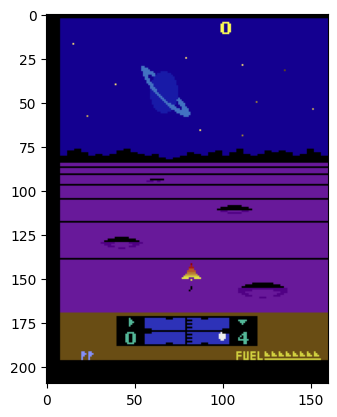  

In [6]:
# The game state appears to have some black padding.
# We will trim these pixels.
# The function is defined above so it can be used for live rendering.
if False: 
    with create_env('ALE/Solaris-v5', render_mode='rgb_array') as env:
        # TODO change to actual observation
        plt.imshow(env.render()[2:-13, 8:, :])

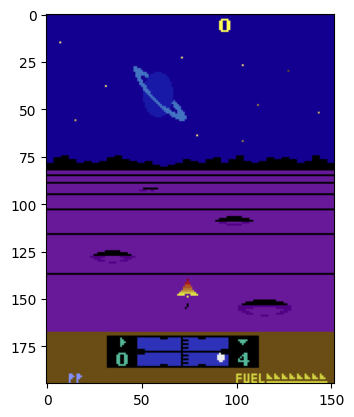

In [7]:
# Looking back at the solaris page on the gymnasium website there is an alternative observation space that is just 128 values.
# This is because the Atari 2600 only had 128 bytes of RAM and with this mode the agent has direct access to these values.
if False:
    with create_env('ALE/Solaris-v5', obs_type='ram') as env:
        print(f'Action Space: {env.action_space}')
        print(f'State space: {env.observation_space}')

```python
Action Space: Discrete(18)
State space: Box(0, 255, (128,), uint8)
```

In [8]:
# There is a caveat with this approach and that is that due to the limited RAM the same slots can be used for different things
# depending on the current game state. The usage of the slot for multiple things is not that big of an issue itself since 
# the network can act on this using the game state but for the network to be able to filter the value the game state should be 
# one-hot encoded.

# I found a copy of the source code of the game online (https://forums.atariage.com/topic/64694-original-source-code/).
# The RAM addresses within the console start at 0x80 so we will subtract this for the indices of the array.
ADDRESS_OFFSET = 0x80

def display_state(env, ram, clear=True):
    frame = env.render()
    ram_grid = ram.reshape((16, 8))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.imshow(trim_frame(frame))
    ax1.axis('off')

    im = ax2.imshow(ram_grid, cmap='viridis', vmin=0, vmax=255)
    ax2.set_title('RAM State')

    for i in range(16):
        for j in range(8):
            location = i * 8 + j + ADDRESS_OFFSET
            color = 'white' if ram_grid[i, j] < 128 else 'black'

            ax2.text(j, i, hex(location), ha='center', va='center', fontsize=7, color=color, alpha=0.5)
            
    plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

    if clear:
        clear_output(wait=True)
    
    display(plt.gcf())
    plt.close(fig)

    for i in range(16):
        for j in range(8):
            print(f'{hex(i * 8 + j + ADDRESS_OFFSET)}: {ram_grid[i, j]:>3}, ', end='')

        print()

In [9]:
if False:
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
            while not episode.done:
                action = env.action_space.sample()
                episode.step(action)
                display_state(env, episode.obs)

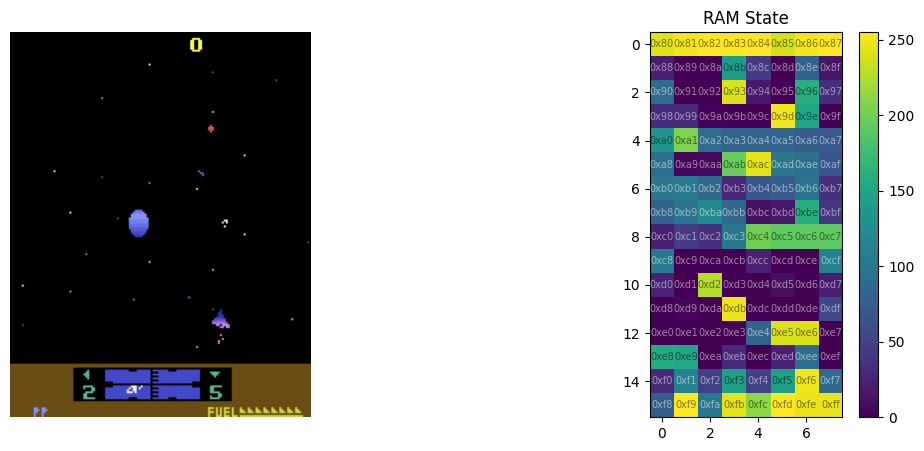

```python
0x80: 243, 0x81: 251, 0x82: 255, 0x83: 254, 0x84: 255, 0x85: 239, 0x86: 251, 0x87: 255, 
0x88:  21, 0x89:   0, 0x8a:   0, 0x8b: 140, 0x8c:  43, 0x8d:   0, 0x8e:  78, 0x8f:  14, 
0x90:  89, 0x91:   0, 0x92:   0, 0x93: 241, 0x94:  17, 0x95:   0, 0x96: 160, 0x97:  32, 
0x98:  32, 0x99:  30, 0x9a:   2, 0x9b:   1, 0x9c:   0, 0x9d: 250, 0x9e: 151, 0x9f:   0, 
0xa0: 133, 0xa1: 206, 0xa2:  90, 0xa3:  83, 0xa4:  83, 0xa5:  83, 0xa6:  75, 0xa7:  71, 
0xa8:  93, 0xa9:   4, 0xaa:   5, 0xab: 196, 0xac: 245, 0xad: 101, 0xae:  94, 0xaf:  68, 
0xb0: 101, 0xb1: 105, 0xb2:  88, 0xb3:  29, 0xb4:  67, 0xb5:  74, 0xb6:  97, 0xb7:  34, 
0xb8:  78, 0xb9:  98, 0xba: 121, 0xbb:  86, 0xbc:  11, 0xbd:  16, 0xbe: 160, 0xbf:  38, 
0xc0:  21, 0xc1:  45, 0xc2:  34, 0xc3: 102, 0xc4: 200, 0xc5: 192, 0xc6: 192, 0xc7: 192, 
0xc8: 104, 0xc9:   0, 0xca:   0, 0xcb:   0, 0xcc:  23, 0xcd:   0, 0xce:   0, 0xcf: 112, 
0xd0:  24, 0xd1:   0, 0xd2: 227, 0xd3:   0, 0xd4:   0, 0xd5:  10, 0xd6:   0, 0xd7:  21, 
0xd8:   0, 0xd9:   3, 0xda:   1, 0xdb: 248, 0xdc:   0, 0xdd:   0, 0xde:   0, 0xdf:  55, 
0xe0:   0, 0xe1:   0, 0xe2:   0, 0xe3:   0, 0xe4:  82, 0xe5: 240, 0xe6: 242, 0xe7:   0, 
0xe8: 157, 0xe9: 152, 0xea:   0, 0xeb:  31, 0xec:   0, 0xed:  23, 0xee:  89, 0xef:   0, 
0xf0:  30, 0xf1: 112, 0xf2:  48, 0xf3: 144, 0xf4:  48, 0xf5: 144, 0xf6: 250, 0xf7:  88, 
0xf8:  75, 0xf9: 255, 0xfa: 102, 0xfb: 245, 0xfc: 212, 0xfd: 255, 0xfe: 248, 0xff: 248,
```

In [10]:
# I will use these techniques to figure out what each address corresponds to: 
# https://github.com/mila-iqia/atari-representation-learning/blob/master/notebooks/atari_guess_n_check.ipynb
ACTIONS = {
    'NOOP': 0,
    'FIRE': 1,
    'UP': 2,
    'RIGHT': 3,
    'LEFT': 4,
    'DOWN': 5,
    'UPRIGHT': 6,
    'UPLEFT': 7,
    'DOWNRIGHT': 8,
    'DOWNLEFT': 9,
    'UPFIRE': 10,
    'RIGHTFIRE': 11,
    'LEFTFIRE': 12,
    'DOWNFIRE': 13,
    'UPRIGHTFIRE': 14,
    'UPLEFTFIRE': 15,
    'DOWNRIGHTFIRE': 16,
    'DOWNLEFTFIRE': 17,
}

if False:
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
            display_state(env, episode.obs, clear=False)
            episode.step(ACTIONS['NOOP'])
            display_state(env, episode.obs, clear=False)

In [11]:
if False:
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
                while not episode.done:
                    episode.step(ACTIONS['FIRE'])
                    display_state(env, episode.obs)
                    episode.step(ACTIONS['NOOP'])
                    display_state(env, episode.obs)

## Reinforcement Learning
I found some webpages where they also did reinforcement learning on Solaris: 
 - https://www.wizwand.com/sota/reinforcement-learning-on-atari-2600-solaris (2 279)
 - https://www.endtoend.ai/envs/gym/atari/solaris/ (3 387)
 - https://arxiv.org/html/2411.03820v1 (8 198)
 - https://huggingface.co/edbeeching/atari_2B_atari_solaris_1111 (3 494)
 - https://arxiv.org/pdf/2003.13350 (44 199)

The goal is to obtain a better score than them and preferably also beat the game but this is a difficult Atari games.

Since the state space is continuous, it won't be possible to use Q-learning or SARSA and these methods need every state to be visited (and often multiple times). They also need at least 1 action to select per state so the memory requirements will be really large. 

For models using gradient updates it will be important to use a scaling mechanism for the RAM observations since some values have larger ranges than other. Normalized rewards also help gradient descend and ascend. For systems like NEAT this isn't an issue since the parameters are derived from random mutations in the evolution process.

The first method that I would like to try is PPO since it is considered one of the best reinforcement learning algorithms and it requires minimal hyperparameter tuning. I will start with the default parameters of the Stable Baselines 3 version of PPO on the RAM observations. We don't need to use frame stacking on the RAM observations since if there is something like velocity for the player or enemies then it must be in the RAM or the game couldn't use it either. For the screenshots this isn't the case since you can't see the direction something is traveling towards on a single image.

There is however a big problem with just training an algorithm and evaluating it. Reinforcement learning suffers from large variances in results based on initial conditions derived from the seed. Running the same training twice with different seeds can give large differences in performance making changes hard to compare (https://arxiv.org/pdf/2304.01315). That is why a lot of researchers run the same training five times but other research suggests that that might not even be enough for a 95% confidence interval (https://www.alexirpan.com/2018/02/14/rl-hard.html and https://arxiv.org/pdf/2406.16241). A popular technique in RL for getting the population distribution is sample bootstrapping (https://arxiv.org/pdf/1709.06560) and I will also use this for meaningfull 95% confidence intervals. I will do this using Rliable (https://github.com/google-research/rliable) which will also be used for the other metrics.

If we had more time for this project I would have loved to try a hybrid approach where the dogfighting is handled by a model-free agent using deep learning and the navigation through the galaxy by an A* algorithm using heuristics to get to Solaris as fast as possible.

**Results**
| Name            | Steps | Runs | Reward IQM + 95% CI  | Reward Mean               | Reward Median | Dist Reward IQM + 95% CI | Dist Reward Mean          | Reward Median |
| --------------- | ----- | ---- | -------------------- | ------------------------- | ------------- | ------------------------ | ------------------------- | ------------- |
| Agent57         | 90B   | 1    | n/a                  | 44 200 ± 8 056            | n/a           | n/a                      | n/a                       | n/a           |
| Random          | n/a   | n/a  | n/a                  | n/a                       | n/a           | 2 150 [2 021, 2 287]     | 2 325 ± 1 398 [0, 10 180] | 2 070         |
| PPO RAM         | 10M   | 5    | 95 [12, 231]         |    112 ± 432 [0, 2 980]   | 0             |                          |                           |               |
| PPO RAM Zoo     | 10M   | 5    |  0 [0, 0]            |      0 ±   0 [0, 0]       | 0             | 2 217 [1 990, 2 472]     | 2 214 ± 1 462 [0, 10 840] | 1 970         |

*Note: The values in the brackets after the IQM are the 95% confidence interval of the IQM.*  
*Note: The mean column also contains the standard deviation, min and max.*

### Validation

In [54]:
VALIDATION_SAMPLES = 50

def evaluate(experiment_name, runs, pick_best_action=True):
    seeds = range(1, runs + 1) 
    runs_rewards = []
    runs_steps = []

    for run in seeds:
        eval_env = DummyVecEnv([lambda: gym.make('ALE/Solaris-v5', obs_type='ram')])
        eval_env = VecNormalize.load(f'runs/{experiment_name}/vec_normalize_{run}.pkl', eval_env)
        eval_env.training = False
        eval_env.norm_reward = False

        model = PPO.load(f'runs/{experiment_name}/{run}', env=eval_env, device='cpu')

        rewards = []
        steps = []

        eval_env.action_space.seed(42 + run)

        for _ in range(VALIDATION_SAMPLES):
            obs = eval_env.reset()
            obs, _, _, info = eval_env.step([ACTIONS['FIRE']])
            done = False
            lives = info[0].get('lives', 0)
            ep_rew = 0
            ep_steps = 0

            while not done:
                action, _ = model.predict(obs, deterministic=pick_best_action)
                obs, reward, done, info = eval_env.step(action)

                if (current_lives := info[0].get('lives', 0)) < lives and not done:
                    obs, _, _, info = eval_env.step([ACTIONS['NOOP']])
                    obs, _, _, info = eval_env.step([ACTIONS['FIRE']])
                    lives = current_lives

                ep_rew += reward[0]
                ep_steps += 1

            rewards.append(ep_rew)
            steps.append(ep_steps)
        
        runs_rewards.append(rewards)
        runs_steps.append(steps)

    data = []

    for i, run_seed in enumerate(seeds):
        for sample_idx in range(VALIDATION_SAMPLES):
            data.append({
                'seed': run_seed,
                'sample': sample_idx,
                'reward': runs_rewards[i][sample_idx],
                'steps': runs_steps[i][sample_idx],
                'truncated': 1 if runs_steps[i][sample_idx] == 26999 else 0,
            })

    df = pd.DataFrame(data)
    df.to_csv(f'runs/{experiment_name}/results{"_probabilities" if not pick_best_action else ""}.csv', index=False)

    return runs_rewards, runs_steps

REPS = 5_000

def show_results(runs_rewards):
    seed_scores = np.mean(runs_rewards, axis=1)
    rewards_matrix = seed_scores.reshape(-1, 1)

    score_dict = {'results': rewards_matrix}

    iqms, intervals = rly.get_interval_estimates(
        score_dict, 
        metrics.aggregate_iqm, 
        reps=REPS,
    )

    print(f'IQM: {iqms["results"]:.2f} [{intervals["results"][0][0]:.2f}, {intervals["results"][1][0]:.2f}]')
    print(f'Mean: {np.mean(runs_rewards):.2f} ± {np.std(runs_rewards):.2f}')
    print(f'Median: {np.median(runs_rewards):.2f}')
    print(f'Min: {np.min(runs_rewards):.2f}, Max: {np.max(runs_rewards):.2f}')

def create_video(experiment_name, run, pick_best_action=True):
    model = PPO.load(f'runs/{experiment_name}/{run}', device='cpu')

    env = gym.make('ALE/Solaris-v5', render_mode='rgb_array', obs_type='ram')
    env = DummyVecEnv([lambda: env])
    env = VecNormalize.load(f'runs/{experiment_name}/vec_normalize_{run}.pkl', env)

    env.training = False
    env.norm_reward = False

    env = VecVideoRecorder(env, f'./runs/{experiment_name}', lambda x: x == 0, video_length=27_000, name_prefix=f'{experiment_name}_{run}')

    done = False

    obs = env.reset()

    obs, _, _, info = env.step([ACTIONS['FIRE']])
    lives = info[0].get('lives', 0)

    while not done:
        action, _ = model.predict(obs, deterministic=pick_best_action)
        obs, _, done, info = env.step(action)

        if (current_lives := info[0].get('lives', 0)) < lives and not done:
            obs, _, _, info = env.step([ACTIONS['NOOP']])
            obs, _, _, info = env.step([ACTIONS['FIRE']])
            lives = current_lives

    env.close()

### Random

In [13]:
# We will first test a random policy as a baseline
if False:
    with create_env('ALE/Solaris-v5', render_mode='rgb_array', max_episode_steps=30_000) as env:
        env = RecordVideo(env, video_folder='./runs/random', name_prefix='random', episode_trigger=lambda _: True)

        with create_episode(env) as episode:
            while not episode.done:
                action = env.action_space.sample()
                episode.step(action)

        env.close()

In [14]:
if False:
    random_runs_rewards = []
    seed_rewards = []

    with create_env('ALE/Solaris-v5', render_mode='rgb_array', max_episode_steps=26_999) as env:
        for _ in range(VALIDATION_SAMPLES * 5):
            with create_episode(env) as episode:
                total_reward = 0

                while not episode.done:
                    action = env.action_space.sample()
                    episode.step(action)
                    total_reward += episode.reward
                
                seed_rewards.append(total_reward)

    rewards_matrix = np.array(seed_rewards).reshape(-1, 1)
    show_results(rewards_matrix.tolist())

```python
IQM: 2150.00 [2021.42, 2287.15]
Mean: 2325.20 ± 1397.81
Median: 2070.00
Min: 0.00, Max: 10180.00
```

### PPO RAM

In [15]:
# I did the actual training in a separate Python file since subprocesses don't work well in notebooks
def train(run):
    train_env = make_vec_env('ALE/Solaris-v5', n_envs=8, seed=42 + run, vec_env_cls=SubprocVecEnv, env_kwargs={'obs_type': 'ram'})
    train_env = VecNormalize(train_env)

    model = PPO('MlpPolicy', train_env, seed=42 + run, device='cpu', tensorboard_log='./runs/logs/')
    model.learn(total_timesteps=10_000_000, progress_bar=True)

    model.save(f'runs/ppo_ram/{run}')
    train_env.save(f'runs/ppo_ram/vec_normalize_{run}.pkl')

if __name__ == '__main__' and False:
    train(1)

In [16]:
if False:
    runs_rewards, runs_steps = evaluate('ppo_ram', 5)
    show_results(runs_rewards)

```python
IQM: 95.20 [12.00, 231.20]
Mean: 112.48 ± 432.17
Median: 0.00
Min: 0.00, Max: 2980.00
```

In [ ]:
if False:
    runs_rewards, runs_steps = evaluate('ppo_ram', 5, pick_best_action=False)
    show_results(runs_rewards)

In [ ]:
if False:
    model = PPO.load('runs/ppo_ram/5', device='cpu')

    env = gym.make('ALE/Solaris-v5', render_mode='rgb_array', obs_type='ram')
    env = DummyVecEnv([lambda: env])
    env = VecNormalize.load('runs/ppo_ram/vec_normalize_5.pkl', env)

    env.training = False
    env.norm_reward = False

    env = VecVideoRecorder(env, './runs/ppo_ram', lambda x: x == 0, video_length=27_000, name_prefix='ppo_ram')

    done = False

    obs = env.reset()

    obs, _, _, _ = env.step([ACTIONS['FIRE']])

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, done, info = env.step(action)
        
    env.close()

### PPO RAM ZOO
The results of the initial model isn't great and there is a lot of variance in rewards across runs. The training is also really noisy. Looking at some video's of episodes the model often doesn't actually seek out combat by navigating to the correct places on the map. 

The Stable Baselines 3 zoo provides a document with better default hyperparameters. Before search these parameters I first want to benchmark with this configuration (https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/ppo.yml). I will use the default Atari configuration since there is no specific one available for Solaris. The step count is greatly decreased to 128 per update so hopefully it will learn more in those 10M steps. The batch size increases from 64 to 256 which will hopefully make learning more stable. They also use the entropy coefficient making it explore more and maybe this will make it learn to seek out enemies. Lastly the learning rate decreases over time so it doesn't unlearn things too often and converges at the end. 


In [18]:
def linear_schedule(initial_value: float):
    def func(progress_remaining: float):
        return progress_remaining * initial_value
    
    return func

def train(run):
    train_env = make_vec_env('ALE/Solaris-v5', n_envs=8, seed=42 + run, vec_env_cls=SubprocVecEnv, env_kwargs={'obs_type': 'ram'})
    train_env = VecNormalize(train_env)

    model = PPO(
        'MlpPolicy', 
        train_env, 
        seed=42 + run, 
        device='cpu', 
        tensorboard_log='./runs/logs/',
        n_steps=128,
        batch_size=256,
        n_epochs=4,
        learning_rate=linear_schedule(2.5e-4),
        clip_range=linear_schedule(0.1),
        vf_coef=0.5,
        ent_coef=0.01,
    )

    model.learn(total_timesteps=10_000_000, progress_bar=True)

    model.save(f'runs/ppo_ram_zoo/{run}')
    train_env.save(f'runs/ppo_ram_zoo/vec_normalize_{run}.pkl')

if __name__ == '__main__' and False:
    train(1)

In [ ]:
if False:
    runs_rewards, runs_steps = evaluate('ppo_ram_zoo', 5)
    show_results(runs_rewards)

```python
IQM: 0.00 [0.00, 0.00]
Mean: 0.00 ± 0.00
Median: 0.00
Min: 0.00, Max: 0.00
```

In [ ]:
if False:
    runs_rewards, runs_steps = evaluate('ppo_ram_zoo', 5, pick_best_action=False)
    show_results(runs_rewards)

```python
IQM: 2216.93 [1990.40, 2471.60]
Mean: 2214.40 ± 1461.63
Median: 1970.00
Min: 0.00, Max: 10840.00
```

In [ ]:
model = PPO.load('runs/ppo_ram_zoo/5', device='cpu')

env = gym.make('ALE/Solaris-v5', render_mode='rgb_array', obs_type='ram')
env = DummyVecEnv([lambda: env])
env = VecNormalize.load('runs/ppo_ram_zoo/vec_normalize_5.pkl', env)

env.training = False
env.norm_reward = False

env = VecVideoRecorder(env, './runs/ppo_ram_zoo', lambda x: x == 0, video_length=27_000, name_prefix='ppo_ram_zoo')

done = False

obs = env.reset()

obs, _, _, info = env.step([ACTIONS['FIRE']])
lives = info[0].get('lives', 0)

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, done, info = env.step(action)

    if (current_lives := info[0].get('lives', 0)) < lives and not done:
        obs, _, _, info = env.step([ACTIONS['NOOP']])
        obs, _, _, info = env.step([ACTIONS['FIRE']])
        lives = current_lives

env.close()

MoviePy - Building video c:\Users\timpi\Documents\Howest\Reinforcement Learning\Project\runs\ppo_ram_zoo\ppo_ram_zoo-step-0-to-step-27000.mp4.
MoviePy - Writing video c:\Users\timpi\Documents\Howest\Reinforcement Learning\Project\runs\ppo_ram_zoo\ppo_ram_zoo-step-0-to-step-27000.mp4



MoviePy - Done !
MoviePy - video ready c:\Users\timpi\Documents\Howest\Reinforcement Learning\Project\runs\ppo_ram_zoo\ppo_ram_zoo-step-0-to-step-27000.mp4


### PPO RAM Time

### PPO RAM Optuna
The Stable Baselines 3 documentation is a great resource for learning RL. They include many links to usefull papers and blog posts. One of those is a post for automatic hyperparameter optimization (https://araffin.github.io/post/hyperparam-tuning/). It is a much smarter way to find the best parameters when compared to a grid search or a random search. Like a halving grid search it prunes parameter values as time goes on but apart from the pruner it has another mechanism called the sampler which I find much more interesting. 

With a grid search the spacing is really important since you can easily miss the global minima of a parameter but making the spacing small requires vast amounts of computation. Grid search also scales exponentially based on the number of hyperparameters and their values to try. Random search has a higher change to find a good value but it also requires lots of computation and the samples have to be increased as the dimensions grow or the samples will be too sparse. 

What the sampler actually uses is Bayesian optimization which goes as follows. This technique builds a model that tries to follow the real reward (dotted line) of a parameter for each of its values. It also models uncertainty for each value (blue area). We start with two samples before creating the model. As you can see in the image the uncertainty around the sampled values is lower than further away from them. The next part of this system is the acquisition function which chooses the next point to sample. In this case the acquisition function samples the point that has the highest expected reward with the uncertainty included. Other functions might take the uncertainty into account and only choose points that we are more confident in. Then the algorithm calculates the reward for that sample and the process repeats until there are no more improvements.
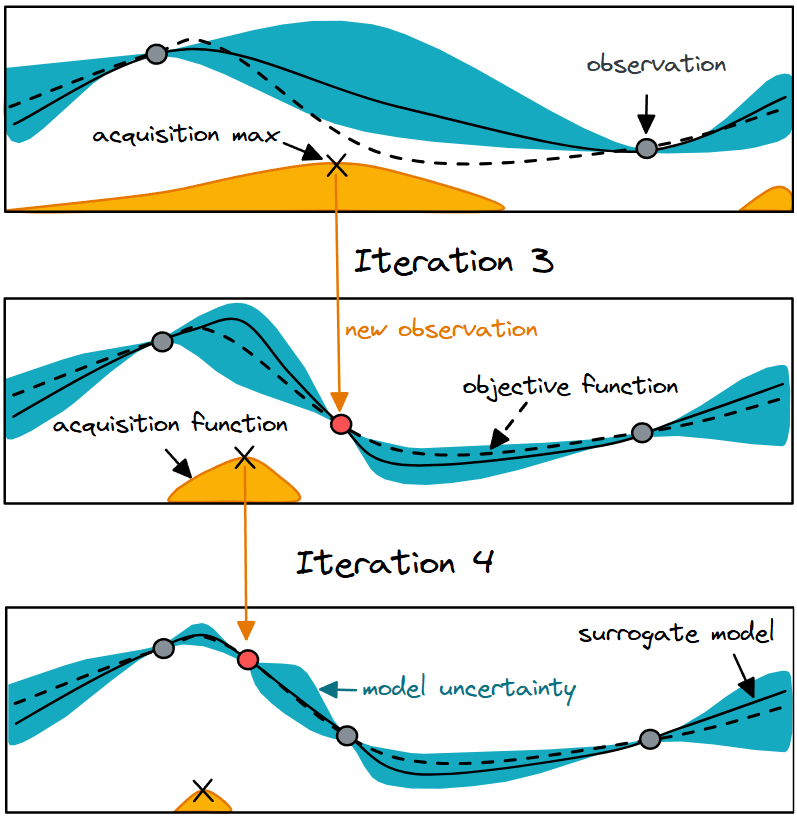

Let's now talk about the pruner. Two popular pruners one of which is the median pruner, which prunes trials that perform worse than the mean of all the trials at the same time step. It is a simple and robust method but you have a higher risk of losing good configuration too early. Another pruner is the successive halving pruner which prunes n% of configurations every m steps and first warms up every configuration o steps. As you cann see we have another 3 hyperparameters to tune with this pruner. This can also be automated and hyperband is an example of this which uses a grid search for this. This method therefore uses more computation but can yield better results.

Due to the time constraints of the project I will implement the median pruner using the Optuna library which works nicely with Stable Baselines 3.